# Day 14 – AI Agent from scratch: tool calling + the ReAct loop

**Goal:** build an agent **without any agent framework**, so every step is visible:
the model **reasons**, **chooses a tool**, we **run it**, the model **sees the result**, and this repeats until it gives a final answer.

**Plan**
1. Four tools as Python functions + JSON schemas: calculator, web search, Day 13 paper search (RAG), today's date
2. Native tool calling with the Gemini API (the model picks the tool and its arguments)
3. The agent loop, with a maximum number of steps
4. Test on 10 multi-step questions, log every step, report success rate and failures

Runtime: **CPU is enough**.

**API key:** native tool calling needs a Gemini API key (free at aistudio.google.com).
Add it in Colab **Secrets** (key icon on the left) as `GEMINI_API_KEY` and turn on notebook access.
Without a key the notebook still runs, but with a **prompt-based** fallback (the model writes the tool call as JSON text) instead of native tool calling.

## 0. Setup

In [1]:
!pip install -q -U google-genai ddgs faiss-cpu pypdf

import os, re, json, time, math, ast, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

MAX_STEPS = 8        # safety limit: the agent stops after this many model calls
RPM = 10             # max Gemini calls per minute (free tier)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


## 1. The tools
Each tool = a normal Python function + a **JSON schema** that tells the model what the tool does and which arguments it takes.
Tools always return text, and they **never crash the agent**: errors are returned as text so the model can try again.

In [2]:
# ---- Tool 1: calculator (safe: only maths, no other Python code can run)
SAFE_FUNCS = {"sqrt": math.sqrt, "round": round, "abs": abs, "log": math.log, "log10": math.log10,
              "pow": pow, "min": min, "max": max, "floor": math.floor, "ceil": math.ceil}
SAFE_NAMES = {"pi": math.pi, "e": math.e}

def _eval(node):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp):
        ops = {ast.Add: lambda a, b: a + b, ast.Sub: lambda a, b: a - b, ast.Mult: lambda a, b: a * b,
               ast.Div: lambda a, b: a / b, ast.FloorDiv: lambda a, b: a // b, ast.Mod: lambda a, b: a % b,
               ast.Pow: lambda a, b: a ** b}
        return ops[type(node.op)](_eval(node.left), _eval(node.right))
    if isinstance(node, ast.UnaryOp) and isinstance(node.op, (ast.USub, ast.UAdd)):
        v = _eval(node.operand)
        return -v if isinstance(node.op, ast.USub) else v
    if isinstance(node, ast.Call) and isinstance(node.func, ast.Name) and node.func.id in SAFE_FUNCS:
        return SAFE_FUNCS[node.func.id](*[_eval(a) for a in node.args])
    if isinstance(node, ast.Name) and node.id in SAFE_NAMES:
        return SAFE_NAMES[node.id]
    raise ValueError(f"not allowed: {ast.dump(node)[:60]}")

def calculator(expression: str) -> str:
    expr = re.sub(r"(?<=\d),(?=\d{3})", "", expression).replace("^", "**").replace("×", "*")
    try:
        result = _eval(ast.parse(expr, mode="eval").body)
        if isinstance(result, float):
            result = round(result, 6)
        return str(result)
    except Exception as e:
        return f"Error: could not calculate '{expression}' ({e})"

# ---- Tool 2: web search (DuckDuckGo, falls back to Wikipedia)
def web_search(query: str) -> str:
    try:
        from ddgs import DDGS
        hits = DDGS().text(query, max_results=4)
        if hits:
            return "\n\n".join(f"- {h['title']}: {h['body']} ({h['href']})" for h in hits)
    except Exception as e:
        print("   (DuckDuckGo failed, using Wikipedia:", str(e)[:60], ")")
    try:
        H = {"User-Agent": "day14-agent-intern-project/1.0"}
        api = "https://en.wikipedia.org/w/api.php"
        s = requests.get(api, headers=H, timeout=20, params={"action": "query", "list": "search",
                         "srsearch": query, "format": "json", "srlimit": 3}).json()
        titles = [r["title"] for r in s["query"]["search"]]
        if not titles:
            return "No results found."
        x = requests.get(api, headers=H, timeout=20, params={"action": "query", "prop": "extracts", "exintro": 1,
                         "explaintext": 1, "titles": "|".join(titles), "format": "json"}).json()
        pages = x["query"]["pages"].values()
        return "\n\n".join(f"- {p['title']} (Wikipedia): {p.get('extract', '')[:700]}" for p in pages)
    except Exception as e:
        return f"Error: search failed ({e})"

# ---- Tool 4: today's date
def get_today() -> str:
    return datetime.date.today().strftime("%A, %d %B %Y")

print(calculator("14,000,000 / 1000"), "|", calculator("sqrt(1889)"), "|", calculator("import os"))
print(get_today())
print(web_search("capital of Japan")[:300])

14000.0 | 43.462628 | Error: could not calculate 'import os' (invalid syntax (<unknown>, line 1))
Monday, 02 November 2026
- Capital of Japan: The capital of Japan is Tokyo. Throughout its history, Japan has had capitals at locations other than Tokyo. Heijō-kyō, in present-day Nara, became the imperial capital in 710, following earlier capitals in the Asuka and Fujiwara areas. Kyoto served as the imperial capital from 7


### Tool 3: search the AI papers (the Day 13 RAG index)
Rebuilds the Day 13 index (5 arXiv papers → recursive chunks → MiniLM → FAISS → cross-encoder re-ranking). Takes about 1–2 minutes on CPU.

In [3]:
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer, CrossEncoder
import faiss

PAPERS = {"Transformer (Attention Is All You Need)": "1706.03762", "BERT": "1810.04805",
          "RAG (Lewis et al.)": "2005.11401", "Sentence-BERT": "1908.10084", "LoRA": "2106.09685"}
os.makedirs("docs", exist_ok=True)

def download(arxiv_id):
    path = f"docs/{arxiv_id}.pdf"
    if os.path.exists(path) and os.path.getsize(path) > 10_000:
        return path
    for url in [f"https://arxiv.org/pdf/{arxiv_id}", f"https://export.arxiv.org/pdf/{arxiv_id}"]:
        try:
            r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
            if r.ok and r.content[:4] == b"%PDF":
                open(path, "wb").write(r.content); return path
        except Exception:
            pass
        time.sleep(3)
    raise RuntimeError(f"Could not download {arxiv_id}")

def clean(t):
    t = re.sub(r"-\n(\w)", r"\1", t); t = re.sub(r"[ \t]+", " ", t)
    return re.sub(r"\n{3,}", "\n\n", t).strip()

def recursive_chunks(text, size=800, seps=("\n\n", "\n", ". ", " ")):
    if len(text) <= size:
        return [text]
    sep = next((s for s in seps if s in text), None)
    if sep is None:
        return [text[i:i + size] for i in range(0, len(text), size)]
    out, cur = [], ""
    for piece in [x + sep for x in text.split(sep)]:
        if len(piece) > size:
            if cur: out.append(cur); cur = ""
            out.extend(recursive_chunks(piece, size, seps[seps.index(sep) + 1:] or (" ",)))
        elif len(cur) + len(piece) <= size:
            cur += piece
        else:
            out.append(cur); cur = piece
    if cur: out.append(cur)
    return [c.strip() for c in out if c.strip()]

rows = []
for name, aid in PAPERS.items():
    for i, page in enumerate(PdfReader(download(aid)).pages):
        for c in recursive_chunks(clean(page.extract_text() or "")):
            if len(c) > 40:
                rows.append({"doc": name, "page": i + 1, "text": c})
chunks = pd.DataFrame(rows)

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2", device="cpu")
vecs = embedder.encode(chunks.text.tolist(), batch_size=32, normalize_embeddings=True).astype("float32")
index = faiss.IndexFlatIP(vecs.shape[1]); index.add(vecs)
print(f"Paper index ready: {len(chunks)} chunks")

def search_papers(query: str) -> str:
    q = embedder.encode([query], normalize_embeddings=True).astype("float32")
    _, ids = index.search(q, 10)
    hits = chunks.iloc[ids[0]].copy()
    hits["score"] = reranker.predict([(query, t) for t in hits.text])
    hits = hits.sort_values("score", ascending=False).head(3)
    return "\n\n".join(f"[{r.doc}, page {r.page}]\n{r.text[:700]}" for r in hits.itertuples())

print(search_papers("How many parameters does BERT-Large have?")[:400])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (12 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Paper index ready: 434 chunks
[BERT, page 8]
with 100M parameters for the encoder, and the
largest Transformer we have found in the literature
is (L=64, H=512, A=2) with 235M parameters
(Al-Rfou et al., 2018). By contrast, BERT BASE
contains 110M parameters and BERT LARGE contains 340M parameters.
It has long been known that increasing the
model size will lead to continual improvements
on large-scale tasks such as machine tran


### The tool registry (functions + JSON schemas)
This is what the model sees. Clear descriptions matter: the model decides which tool to use **only** from these descriptions.

In [4]:
TOOLS = {
    "calculator": {
        "function": calculator,
        "description": "Evaluate a maths expression and return the exact result. Use it for ALL arithmetic. "
                       "Supports + - * / // % ** and sqrt, round, abs, log, log10, pow, min, max, floor, ceil, pi, e.",
        "parameters": {"type": "object",
                       "properties": {"expression": {"type": "string", "description": "e.g. '14000000 / 1000' or 'round(sqrt(1889), 2)'"}},
                       "required": ["expression"]},
    },
    "web_search": {
        "function": web_search,
        "description": "Search the web for facts about the world (people, places, populations, dates, heights...). "
                       "Returns short snippets.",
        "parameters": {"type": "object",
                       "properties": {"query": {"type": "string", "description": "a short search query"}},
                       "required": ["query"]},
    },
    "search_papers": {
        "function": search_papers,
        "description": "Search 5 AI research papers (Transformer 'Attention Is All You Need', BERT, RAG, Sentence-BERT, LoRA) "
                       "and return the most relevant passages with paper name and page. Use it for questions about these papers.",
        "parameters": {"type": "object",
                       "properties": {"query": {"type": "string", "description": "what to look for in the papers"}},
                       "required": ["query"]},
    },
    "get_today": {
        "function": get_today,
        "description": "Return today's date. Use it when the question depends on the current date or year.",
        "parameters": {"type": "object", "properties": {}},
    },
}

def run_tool(name, args):
    """Run a tool safely. Unknown tools and errors come back as text, never as a crash."""
    if name not in TOOLS:
        return f"Error: unknown tool '{name}'. Available: {list(TOOLS)}"
    try:
        out = TOOLS[name]["function"](**(args or {}))
    except Exception as e:
        out = f"Error running {name}: {e}"
    return str(out)[:2500]

print(json.dumps({k: {"description": v["description"][:60] + "...", "parameters": v["parameters"]} for k, v in TOOLS.items()}, indent=1)[:900])

{
 "calculator": {
  "description": "Evaluate a maths expression and return the exact result. Use...",
  "parameters": {
   "type": "object",
   "properties": {
    "expression": {
     "type": "string",
     "description": "e.g. '14000000 / 1000' or 'round(sqrt(1889), 2)'"
    }
   },
   "required": [
    "expression"
   ]
  }
 },
 "web_search": {
  "description": "Search the web for facts about the world (people, places, po...",
  "parameters": {
   "type": "object",
   "properties": {
    "query": {
     "type": "string",
     "description": "a short search query"
    }
   },
   "required": [
    "query"
   ]
  }
 },
 "search_papers": {
  "description": "Search 5 AI research papers (Transformer 'Attention Is All Y...",
  "parameters": {
   "type": "object",
   "properties": {
    "query": {
     "type": "string",
     "description": "what to look for in the papers"
    }
   },
   "req


## 2. Connect to Gemini (native tool calling)
The tool schemas are sent to Gemini as `FunctionDeclaration`s. When Gemini wants a tool, it does **not** run it: it returns a
`function_call` (tool name + arguments). **Our loop** runs the tool and sends the result back.
Automatic function calling in the SDK is turned **off**, so the loop below is 100% ours.

In [5]:
client, MODEL, colab_ai = None, None, None
try:
    from google.colab import userdata
    key = userdata.get("GEMINI_API_KEY")
except Exception:
    key = os.environ.get("GEMINI_API_KEY")

if key:
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=key)
    available = [m.name.split("/")[-1] for m in client.models.list()]
    MODEL = next((m for m in ["gemini-2.5-flash", "gemini-2.0-flash", "gemini-flash-latest"] if m in available), "gemini-2.5-flash")
    MODE = "native"
    gemini_tools = [types.Tool(function_declarations=[
        types.FunctionDeclaration(name=n, description=t["description"], parameters_json_schema=t["parameters"])
        for n, t in TOOLS.items()])]
    print("Native tool calling with", MODEL)
else:
    from google.colab import ai as colab_ai
    MODE = "prompt-based"
    MODEL = "Gemini (Colab built-in)"
    print("No GEMINI_API_KEY found -> prompt-based tool calling fallback with Colab's built-in model")

_last = [0.0]
def throttle():
    wait = 60 / RPM - (time.time() - _last[0])
    if wait > 0: time.sleep(wait)
    _last[0] = time.time()

def with_retry(fn):
    for attempt in range(5):
        try:
            throttle()
            return fn()
        except Exception as e:
            msg = str(e)
            if any(k in msg for k in ["429", "RESOURCE_EXHAUSTED", "503", "UNAVAILABLE", "500"]):
                print(f"   rate limit / busy, waiting 30s ({msg[:70]})"); time.sleep(30)
            else:
                raise
    raise RuntimeError("Model kept failing")

SYSTEM = """You are a careful research assistant that solves questions step by step using tools.
Rules:
- Before every tool call, write ONE short sentence saying what you need and why.
- Use web_search for world facts, search_papers for the 5 AI papers, get_today for the current date.
- Use calculator for ALL arithmetic, never do maths in your head.
- One step at a time: look at each tool result before deciding the next step.
- When you have everything, give a short final answer with the final number clearly stated.
- If the tools cannot find something, say so instead of guessing."""

No GEMINI_API_KEY found -> prompt-based tool calling fallback with Colab's built-in model


## 3. The agent loop (ReAct: Reason → Act → Observe)
```
question → model ─┬─ final answer? → stop
                  └─ tool call → run tool → add result to the conversation → model again
```
Stops at the final answer or after `MAX_STEPS` model calls. Every step is logged (thought, tool, arguments, result, tokens, time).

In [6]:
def agent_native(question, max_steps=MAX_STEPS, verbose=True):
    log = []
    contents = [types.Content(role="user", parts=[types.Part(text=question)])]
    config = types.GenerateContentConfig(system_instruction=SYSTEM, tools=gemini_tools, temperature=0,
                                         automatic_function_calling=types.AutomaticFunctionCallingConfig(disable=True))
    for step in range(1, max_steps + 1):
        t0 = time.time()
        resp = with_retry(lambda: client.models.generate_content(model=MODEL, contents=contents, config=config))
        u = resp.usage_metadata
        tokens = (u.prompt_token_count or 0) + (u.candidates_token_count or 0) + (getattr(u, "thoughts_token_count", 0) or 0)
        msg = resp.candidates[0].content
        contents.append(msg)                                    # keep the model's turn (incl. its tool calls)
        parts = msg.parts or []
        thought = " ".join(p.text for p in parts if getattr(p, "text", None)).strip()
        calls = [p.function_call for p in parts if getattr(p, "function_call", None)]

        if not calls:                                           # no tool requested -> final answer
            log.append({"step": step, "type": "final", "text": thought, "tokens": tokens, "seconds": time.time() - t0})
            if verbose: print(f"  [{step}] FINAL: {thought}")
            return thought, log

        results = []
        for fc in calls:
            args = dict(fc.args or {})
            out = run_tool(fc.name, args)
            log.append({"step": step, "type": "tool", "thought": thought, "tool": fc.name, "args": args,
                        "result": out[:500], "tokens": tokens, "seconds": time.time() - t0})
            if verbose:
                if thought: print(f"  [{step}] THINK: {thought}")
                print(f"  [{step}] ACT:   {fc.name}({args})")
                print(f"  [{step}] SEE:   {out[:160].replace(chr(10), ' ')}...")
            results.append(types.Part.from_function_response(name=fc.name, response={"result": out}))
            thought = ""
        contents.append(types.Content(role="user", parts=results))   # send tool results back

    log.append({"step": max_steps, "type": "stopped", "text": "Max steps reached", "tokens": 0, "seconds": 0})
    if verbose: print("  STOPPED: max steps reached")
    return "Stopped: max steps reached without a final answer.", log


# ---- Fallback without an API key: the same loop, but the tool call is written as JSON text
FALLBACK_PROMPT = SYSTEM + """

Tools (JSON schemas):
{tools}

Reply with ONLY one JSON object, one of:
{{"thought": "...", "tool": "<tool name>", "args": {{...}}}}
{{"thought": "...", "final_answer": "..."}}

Conversation so far:
{history}"""

def agent_prompt_based(question, max_steps=MAX_STEPS, verbose=True):
    log, history = [], f"User question: {question}"
    schemas = json.dumps({n: {"description": t["description"], "parameters": t["parameters"]} for n, t in TOOLS.items()}, indent=1)
    for step in range(1, max_steps + 1):
        t0 = time.time()
        prompt = FALLBACK_PROMPT.format(tools=schemas, history=history)
        raw = with_retry(lambda: colab_ai.generate_text(prompt))
        tokens = (len(prompt) + len(raw)) // 4                  # estimate (built-in model gives no counts)
        m = re.search(r"\{.*\}", raw, flags=re.S)
        try:
            d = json.loads(m.group(0))
        except Exception:
            history += f"\nAssistant (invalid): {raw[:200]}\nSystem: That was not valid JSON. Reply with one JSON object only."
            log.append({"step": step, "type": "format_error", "text": raw[:300], "tokens": tokens, "seconds": time.time() - t0})
            continue
        if "final_answer" in d:
            log.append({"step": step, "type": "final", "text": str(d["final_answer"]), "thought": d.get("thought", ""),
                        "tokens": tokens, "seconds": time.time() - t0})
            if verbose: print(f"  [{step}] FINAL: {d['final_answer']}")
            return str(d["final_answer"]), log
        name, args = d.get("tool"), d.get("args", {})
        out = run_tool(name, args)
        log.append({"step": step, "type": "tool", "thought": d.get("thought", ""), "tool": name, "args": args,
                    "result": out[:500], "tokens": tokens, "seconds": time.time() - t0})
        if verbose:
            print(f"  [{step}] THINK: {d.get('thought', '')}")
            print(f"  [{step}] ACT:   {name}({args})")
            print(f"  [{step}] SEE:   {out[:160].replace(chr(10), ' ')}...")
        history += f"\nAssistant: {json.dumps(d)}\nTool result ({name}): {out[:1500]}"
    log.append({"step": max_steps, "type": "stopped", "text": "Max steps reached", "tokens": 0, "seconds": 0})
    return "Stopped: max steps reached without a final answer.", log

agent = agent_native if MODE == "native" else agent_prompt_based

print("Q: What is the population of the capital of Japan divided by 1,000?")
answer, demo_log = agent("What is the population of the capital of Japan divided by 1,000?")

Q: What is the population of the capital of Japan divided by 1,000?
  [1] THINK: I need to find the capital of Japan and its population to perform the calculation.
  [1] ACT:   web_search({'query': 'population of Tokyo, Japan'})
  [1] SEE:   - Demographics of Tokyo - Wikipedia: Before Tokyo existed as a major population center, the area was known as Edo, a modest fishing village. Population estimate...
  [2] THINK: I will use the population of Tokyo (10,316,210) provided in the search results to perform the division by 1,000.
  [2] ACT:   calculator({'expression': '10316210 / 1000'})
  [2] SEE:   10316.21...
  [3] FINAL: The population of Tokyo, the capital of Japan, is 10,316,210, which when divided by 1,000 results in 10,316.21.


## 4. Test on 10 multi-step questions
Each question needs **2 or more steps** (find a fact, then calculate). An automatic check looks for the key facts/numbers in the final answer.
Always read the traces too: the automatic check is simple and can be wrong.

In [7]:
YEAR = datetime.date.today().year

def nums(text):
    return [float(x) for x in re.findall(r"-?\d+(?:\.\d+)?", re.sub(r"(?<=\d),(?=\d{3})", "", text))]

def has(*words):
    return lambda a: all(w.lower() in a.lower().replace(",", "") for w in words)

def in_range(*ranges):
    return lambda a: any(lo <= n <= hi for n in nums(a) for lo, hi in ranges)

TESTS = [
    ("What is the population of the capital of Japan divided by 1,000?",
     "Tokyo ~14 million (city) or ~37 million (metro) -> ~14,000 or ~37,000", in_range((13000, 15000), (36000, 38500))),
    ("In what year was the paper 'Attention Is All You Need' published, and how many years ago is that from today?",
     f"2017, {YEAR - 2017} years ago", has("2017", str(YEAR - 2017))),
    ("According to the BERT paper, how many parameters does BERT-Large have? Multiply that number by 2.",
     "340M x 2 = 680M", has("680")),
    ("What BLEU score did the big Transformer get on WMT 2014 English-to-German in the Transformer paper? Add 10 to it.",
     "28.4 + 10 = 38.4", has("38.4")),
    ("In what year was the Eiffel Tower completed? Give the square root of that year, rounded to 2 decimal places.",
     "1889 -> 43.46", has("43.46")),
    ("How tall is Mount Everest in metres, and what is that in feet (1 m = 3.28084 ft)?",
     "8,849 m -> about 29,032 ft", in_range((29000, 29060))),
    ("Who is the first author of the LoRA paper and in what year was it published? How many years before 2030 is that?",
     "Edward Hu, 2021, 9 years", has("Hu", "2021")),
    ("What is the d_model of the base Transformer, and how many dimensions does each head get if it is split across 8 heads?",
     "512 / 8 = 64", has("64")),
    ("How many days are there from 1 January 2026 to 4 February 2026, Sri Lanka's Independence Day?",
     "34 days", has("34")),
    ("What is the boiling point of water at sea level in Fahrenheit? Convert it to Kelvin.",
     "212 F = 373.15 K", has("373")),
]

TRACE_FILE = "day14_trace.jsonl"
done = {}
if os.path.exists(TRACE_FILE):
    for line in open(TRACE_FILE):
        r = json.loads(line); done[r["question"]] = r

for i, (q, expected, check) in enumerate(TESTS, 1):
    if q in done:
        print(f"Q{i} already done"); continue
    print(f"\n=== Q{i}: {q}")
    t0 = time.time()
    try:
        answer, log = agent(q)
    except Exception as e:
        answer, log = f"CRASH: {e}", [{"step": 0, "type": "crash", "text": str(e)}]
    rec = {"question": q, "expected": expected, "answer": answer, "success": bool(check(answer)),
           "steps": max([s["step"] for s in log] + [0]), "tool_calls": sum(s["type"] == "tool" for s in log),
           "tools_used": [s["tool"] for s in log if s["type"] == "tool"],
           "tokens": sum(s.get("tokens", 0) for s in log), "seconds": round(time.time() - t0, 1),
           "stopped": any(s["type"] == "stopped" for s in log), "log": log, "mode": MODE}
    done[q] = rec
    with open(TRACE_FILE, "a") as f:
        f.write(json.dumps(rec, default=str) + "\n")
    print(f"  -> {'SUCCESS' if rec['success'] else 'CHECK FAILED'} (expected: {expected})")


=== Q1: What is the population of the capital of Japan divided by 1,000?
  [1] THINK: I need to find the capital of Japan and its population to perform the calculation.
  [1] ACT:   web_search({'query': 'population of Tokyo, Japan'})
  [1] SEE:   - Demographics of Tokyo - Wikipedia: Before Tokyo existed as a major population center, the area was known as Edo, a modest fishing village. Population estimate...
  [2] THINK: I will use the population of Tokyo (10,316,210) provided in the search results to perform the division by 1,000.
  [2] ACT:   calculator({'expression': '10316210 / 1000'})
  [2] SEE:   10316.21...
  [3] FINAL: The population of Tokyo, the capital of Japan, is 10,316,210, which when divided by 1,000 results in 10,316.21.
  -> CHECK FAILED (expected: Tokyo ~14 million (city) or ~37 million (metro) -> ~14,000 or ~37,000)

=== Q2: In what year was the paper 'Attention Is All You Need' published, and how many years ago is that from today?
  [1] THINK: I need to find the pub

## 5. Results

Mode: prompt-based | Model: Gemini (Colab built-in)
Success rate: 90% (9 of 10)
Average model calls per question: 3.3 | average tool calls: 2.3
Average time per question: 19.8s | average tokens: 3375
Hit the max-steps limit: 0


,Q,success,steps,tool_calls,seconds,answer,expected
0,Q1,False,3,2,17.7,"The population of Tokyo, the capital of Japan, is 10,316,210, which when divided by 1,...","Tokyo ~14 million (city) or ~37 million (metro) -> ~14,000 or ~37,000"
1,Q2,True,4,3,24.0,"The paper 'Attention Is All You Need' was published in 2017, which is 9 years ago from...","2017, 9 years ago"
2,Q3,True,3,2,18.5,"According to the BERT paper, BERT-Large has 340 million parameters. Multiplying this b...",340M x 2 = 680M
3,Q4,True,3,2,17.5,"The BLEU score for the big Transformer model on WMT 2014 English-to-German was 28.4, a...",28.4 + 10 = 38.4
4,Q5,True,3,2,18.6,"The Eiffel Tower was completed in 1889, and the square root of 1889, rounded to 2 deci...",1889 -> 43.46
5,Q6,True,3,2,17.5,"Mount Everest is 8,848.86 meters tall, which is approximately 29,031.69 feet.","8,849 m -> about 29,032 ft"
6,Q7,True,4,3,24.3,"The first author of the LoRA paper is Edward Hu, and it was published in 2021. This is...","Edward Hu, 2021, 9 years"
7,Q8,True,5,4,30.0,"The base Transformer has a d_model of 512, and when split across 8 heads, each head ha...",512 / 8 = 64
8,Q9,True,2,1,12.1,There are 34 days from 1 January 2026 to 4 February 2026.,34 days
9,Q10,True,3,2,17.5,"The boiling point of water at sea level is 212°F, which is equivalent to 373.15 Kelvin.",212 F = 373.15 K


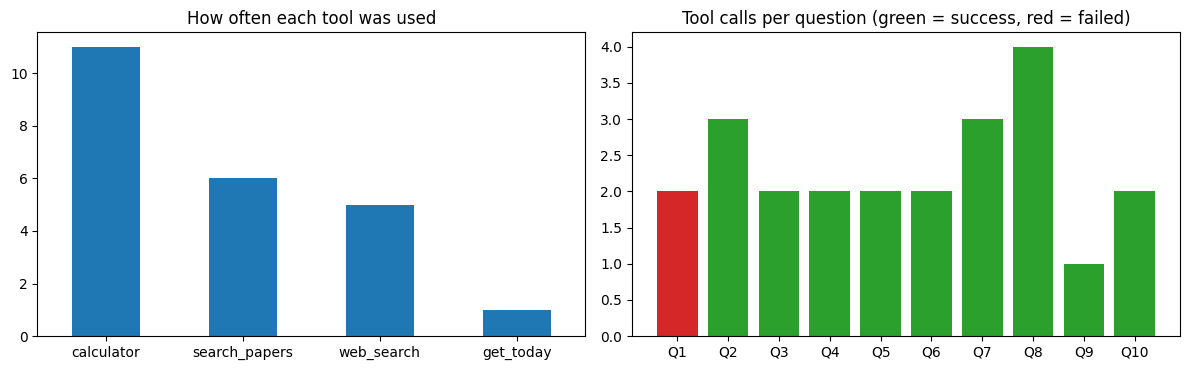

In [8]:
res = pd.DataFrame([done[q] for q, _, _ in TESTS if q in done])
res.insert(0, "Q", [f"Q{i}" for i in range(1, len(res) + 1)])

print(f"Mode: {MODE} | Model: {MODEL}")
print(f"Success rate: {res.success.mean():.0%} ({res.success.sum()} of {len(res)})")
print(f"Average model calls per question: {res.steps.mean():.1f} | average tool calls: {res.tool_calls.mean():.1f}")
print(f"Average time per question: {res.seconds.mean():.1f}s | average tokens: {res.tokens.mean():.0f}")
print(f"Hit the max-steps limit: {res.stopped.sum()}")

pd.set_option("display.max_colwidth", 90)
display(res[["Q", "success", "steps", "tool_calls", "seconds", "answer", "expected"]])

tool_counts = pd.Series([t for ts in res.tools_used for t in ts]).value_counts()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
tool_counts.plot.bar(ax=ax[0], rot=0, color="tab:blue", title="How often each tool was used")
ax[1].bar(res.Q, res.tool_calls, color=["tab:green" if s else "tab:red" for s in res.success])
ax[1].set_title("Tool calls per question (green = success, red = failed)")
plt.tight_layout(); plt.show()

## 6. Failure analysis
For every failed question, the full trace: what the agent thought, which tool it called, and what it saw.
Typical failure types: **wrong tool**, **bad search query**, **tool returned wrong/old data**, **maths done in its head**, **gave up / max steps**, or the **automatic check is too strict** (answer is actually right).

In [9]:
failed = res[~res.success]
if failed.empty:
    print("No failures - read a few traces anyway to check the reasoning is sensible.")
for r in failed.itertuples():
    print(f"\n=== {r.Q}: {r.question}\nExpected: {r.expected}\nAnswer:   {r.answer}")
    for s in r.log:
        if s["type"] == "tool":
            print(f"  [{s['step']}] {s.get('thought', '')[:120]}")
            print(f"       {s['tool']}({s['args']}) -> {str(s['result'])[:150].replace(chr(10), ' ')}")
        else:
            print(f"  [{s['step']}] {s['type'].upper()}: {str(s.get('text', ''))[:150]}")


=== Q1: What is the population of the capital of Japan divided by 1,000?
Expected: Tokyo ~14 million (city) or ~37 million (metro) -> ~14,000 or ~37,000
Answer:   The population of Tokyo, the capital of Japan, is 10,316,210, which when divided by 1,000 results in 10,316.21.
  [1] I need to find the capital of Japan and its population to perform the calculation.
       web_search({'query': 'population of Tokyo, Japan'}) -> - Demographics of Tokyo - Wikipedia: Before Tokyo existed as a major population center, the area was known as Edo, a modest fishing village. Populatio
  [2] I will use the population of Tokyo (10,316,210) provided in the search results to perform the division by 1,000.
       calculator({'expression': '10316210 / 1000'}) -> 10316.21
  [3] FINAL: The population of Tokyo, the capital of Japan, is 10,316,210, which when divided by 1,000 results in 10,316.21.


## 7. Try your own question

In [10]:
_ = agent("What is the capital of Sri Lanka, and what is its population divided by 100?")

  [1] THINK: I need to find the capital of Sri Lanka and its current population to perform the calculation.
  [1] ACT:   web_search({'query': 'capital of Sri Lanka and its population'})
  [1] SEE:   - Sri Lanka - Wikipedia: Its executive and judicial capital is Colombo, which is also its largest city and the political, financial and cultural centre of the c...
  [2] THINK: I will use the calculator to divide the population of Colombo, which is 752,993, by 100.
  [2] ACT:   calculator({'expression': '752993 / 100'})
  [2] SEE:   7529.93...
  [3] FINAL: The executive and judicial capital of Sri Lanka is Colombo, which has a population of 752,993. When divided by 100, the result is 7,529.93.


## My notes (write in your own words)

**How the agent loop works (in my words):**
The LLM reads the question and decides what it needs. If it needs a tool, it says which tool and with what input. My code runs the tool and gives the result back to the LLM. This repeats until the LLM has enough information to give the final answer.
-

**Which questions failed, and why?** (look at section 6)
Q1 failed. The agent used an old Tokyo population number (10.3 million) from a Wikipedia page. The current number is about 14 million. It trusted the search result without checking if it was recent.
Q8 had an error (calculator called with no input), but the agent fixed it on the next step.
Q10 got the right answer using a shortcut (100 + 273.15) instead of converting from Fahrenheit.
-

**Why is MAX_STEPS important?**
Without a limit, the agent could keep calling tools forever if it gets confused, which wastes time and API quota. MAX_STEPS = 8 stops it safely. In my test, no question needed more than 5 steps.
-

**What I would improve next time:**
Use a Gemini API key to test native tool calling.
Tell the agent to prefer the latest data and mention the year of the source.
Test with more questions.
-